# 03 — Evaluation and Experimental Diagnostics


## Research question

What do simple, transparent baselines reveal about the synthetic prediction
tasks, and where do their errors concentrate? The goal is diagnostic comparison,
not a claim that a final world model has been trained.

The main assumption is that modest baselines provide useful reference behavior.
Evidence is evaluated separately for chronological and spatial holdouts. A key
limitation is that all results arise from one fictional generator and do not
measure operational performance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
observations = pd.read_csv("data/generated/observations.csv")
partitions = pd.read_csv("data/generated/partitions.csv")
data = observations.merge(
    partitions.drop(columns="pressure_su"), on=["site_id", "period"], validate="one_to_one"
)
data.shape, data.head()

((864, 14),
   site_id    x_norm    y_norm  period synthetic_month  spatial_component  \
 0     S00  0.369331  0.516951       0         2000-01           0.383147   
 1     S00  0.369331  0.516951       1         2000-02           0.383147   
 2     S00  0.369331  0.516951       2         2000-03           0.383147   
 3     S00  0.369331  0.516951       3         2000-04           0.383147   
 4     S00  0.369331  0.516951       4         2000-05           0.383147   
 
    temporal_component  seasonal_component  perturbation_component  \
 0               0.000            0.000000                     0.0   
 1               0.035            0.175000                     0.0   
 2               0.070            0.303109                     0.0   
 3               0.105            0.350000                     0.0   
 4               0.140            0.303109                     0.0   
 
    site_offset  pressure_su  is_missing chronological_role spatial_role  
 0     0.599744    10.95263

## Recheck evaluation inputs

Predictions are evaluated only where the synthetic target is observed. We
inspect missingness and partition membership before fitting anything. The
generator component columns remain diagnostic evidence and are excluded from
all baseline inputs because using them would leak the constructed answer.

In [3]:
partition_counts = data.groupby(["chronological_role", "spatial_role"])["pressure_su"].agg(
    rows="size", observed="count"
)
partition_counts

rows  observed
chronological_role spatial_role                
test               test            40        35
                   train          152       143
train              test           140       122
                   train          532       501

In [4]:
chron_train = data.query("chronological_role == 'train'").dropna(subset=["pressure_su"]).copy()
chron_test = data.query("chronological_role == 'test'").dropna(subset=["pressure_su"]).copy()
assert chron_train["period"].max() < chron_test["period"].min()
chron_train.shape, chron_test.shape

((623, 14), (178, 14))

In [5]:
def metric_row(name, frame, prediction_column, protocol, domain):
    residual = frame["pressure_su"] - frame[prediction_column]
    return {
        "protocol": protocol, "domain": domain, "baseline": name,
        "n": len(residual), "mae": residual.abs().mean(),
        "rmse": np.sqrt(np.mean(residual**2)), "bias": residual.mean(),
    }

## Baseline 1: training-set mean

The first reference predicts one constant estimated only from chronological
training observations. It ignores site, space, and time. Its value is not
competitive accuracy; it establishes the error scale of a deliberately weak
reference and makes systematic residual structure easy to see.

In [6]:
global_mean = chron_train["pressure_su"].mean()
chron_mean = chron_test.assign(pred_global_mean=global_mean)
chron_mean[["site_id", "period", "pressure_su", "pred_global_mean"]].head()

,site_id,period,pressure_su,pred_global_mean
28,S00,28,12.424960,11.348806
29,S00,29,12.198879,11.348806
30,S00,30,12.119511,11.348806
31,S00,31,11.955993,11.348806
32,S00,32,11.574623,11.348806


In [7]:
mean_metrics = metric_row(
    "global mean", chron_mean, "pred_global_mean",
    "chronological prediction", "periods 28–35; observed test rows",
)
pd.DataFrame([mean_metrics])

,protocol,domain,baseline,n,mae,rmse,bias
0,chronological prediction,periods 28–35; observed test rows,global mean,178,0.60256,0.802759,0.402273


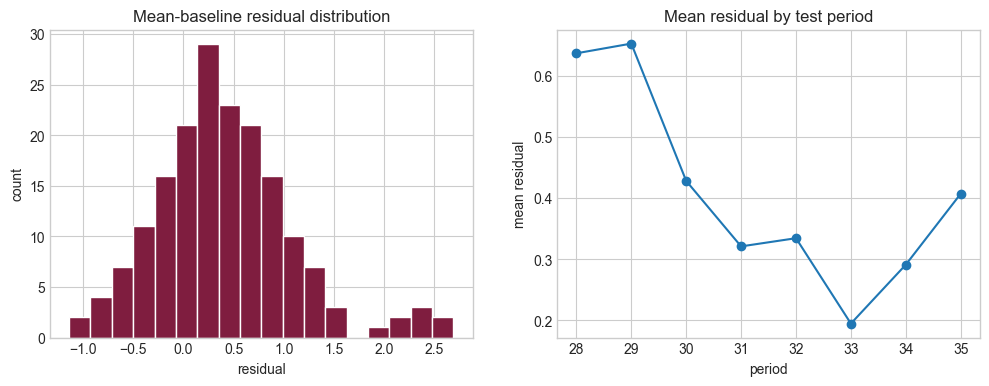

In [8]:
chron_mean["residual"] = chron_mean["pressure_su"] - chron_mean["pred_global_mean"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(chron_mean["residual"], bins=18, color="#7f1d3f", edgecolor="white")
axes[0].set(title="Mean-baseline residual distribution", xlabel="residual", ylabel="count")
chron_mean.groupby("period")["residual"].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="Mean residual by test period", xlabel="period", ylabel="mean residual")
plt.show()

The residual distribution is not centered tightly around zero across all test
periods because the constant baseline cannot follow the designed temporal
change. This supports using the mean as a lower reference, not as an adequate
forecast. The figure does not identify why a real system would change.

## Baseline 2: per-site persistence

Persistence predicts each site's latest observed training value throughout the
later test period. This uses site identity but assumes no continued trend. We
inspect both predictions and residual timing to see where that assumption fails.

In [9]:
latest_rows = chron_train.sort_values("period").groupby("site_id").tail(1)
latest_value = latest_rows.set_index("site_id")["pressure_su"]
chron_persistence = chron_test.assign(
    pred_persistence=chron_test["site_id"].map(latest_value)
)
chron_persistence[["site_id", "period", "pressure_su", "pred_persistence"]].head()

,site_id,period,pressure_su,pred_persistence
28,S00,28,12.424960,12.191252
29,S00,29,12.198879,12.191252
30,S00,30,12.119511,12.191252
31,S00,31,11.955993,12.191252
32,S00,32,11.574623,12.191252


In [10]:
persistence_metrics = metric_row(
    "per-site persistence", chron_persistence, "pred_persistence",
    "chronological prediction", "periods 28–35; observed test rows",
)
pd.DataFrame([mean_metrics, persistence_metrics])

,protocol,domain,baseline,n,mae,rmse,bias
0,chronological prediction,periods 28–35; observed test rows,global mean,178,0.602560,0.802759,0.402273
1,chronological prediction,periods 28–35; observed test rows,per-site persistence,178,0.320228,0.395955,-0.261640


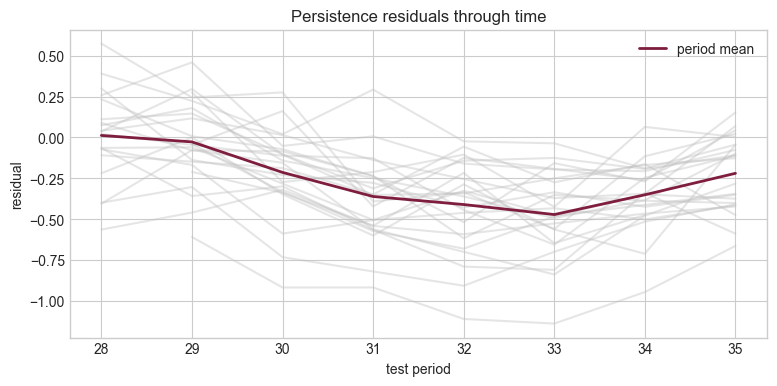

In [11]:
chron_persistence["residual"] = chron_persistence["pressure_su"] - chron_persistence["pred_persistence"]
fig, ax = plt.subplots(figsize=(9, 4))
for site_id, frame in chron_persistence.groupby("site_id"):
    ax.plot(frame["period"], frame["residual"], color="silver", alpha=0.4)
ax.plot(chron_persistence.groupby("period")["residual"].mean(), color="#7f1d3f", linewidth=2, label="period mean")
ax.set(xlabel="test period", ylabel="residual", title="Persistence residuals through time")
ax.legend()
plt.show()

Persistence retains site offsets and therefore changes the error structure, but
its residuals can drift when the synthetic response continues moving. Comparing
it with the global mean reveals which simple assumption matters; it does not
show that persistence is universally appropriate.

## Baseline 3: independent per-site linear trends

Each site receives a straight-line fit using only its observed chronological
training values. This adds one temporal assumption without sharing targets
between sites. Curvature and abrupt changes remain outside the model.

In [12]:
trend_parameters = {}
for site_id, frame in chron_train.groupby("site_id"):
    slope, intercept = np.polyfit(frame["period"], frame["pressure_su"], deg=1)
    trend_parameters[site_id] = (slope, intercept)

chron_trend = chron_test.copy()
chron_trend["pred_linear_trend"] = [
    trend_parameters[row.site_id][0] * row.period + trend_parameters[row.site_id][1]
    for row in chron_trend.itertuples()
]

In [13]:
trend_metrics = metric_row(
    "per-site linear trend", chron_trend, "pred_linear_trend",
    "chronological prediction", "periods 28–35; observed test rows",
)
chronological_metrics = pd.DataFrame([
    mean_metrics, persistence_metrics, trend_metrics,
]).sort_values("rmse")
chronological_metrics

,protocol,domain,baseline,n,mae,rmse,bias
2,chronological prediction,periods 28–35; observed test rows,per-site linear trend,178,0.225458,0.269812,-0.065418
1,chronological prediction,periods 28–35; observed test rows,per-site persistence,178,0.320228,0.395955,-0.261640
0,chronological prediction,periods 28–35; observed test rows,global mean,178,0.602560,0.802759,0.402273


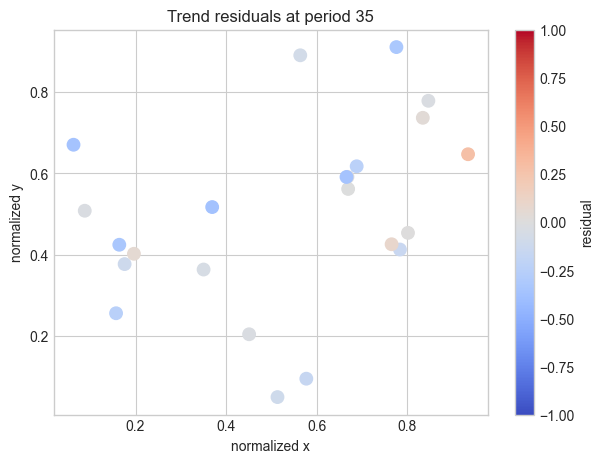

In [14]:
chron_trend["residual"] = chron_trend["pressure_su"] - chron_trend["pred_linear_trend"]
latest_period = chron_trend["period"].max()
latest_residuals = chron_trend.query("period == @latest_period")
fig, ax = plt.subplots(figsize=(7, 5))
points = ax.scatter(latest_residuals["x_norm"], latest_residuals["y_norm"], c=latest_residuals["residual"], cmap="coolwarm", vmin=-1, vmax=1, s=80)
ax.set(xlabel="normalized x", ylabel="normalized y", title=f"Trend residuals at period {latest_period}")
fig.colorbar(points, ax=ax, label="residual")
plt.show()

The comparison table indicates which modest temporal assumption performs best
for this particular later-period split. The residual map still shows spatial
structure, so a low aggregate error would not imply spatially uniform behavior.
Because the data generator includes a nonlinear seasonal term and localized
change, a straight trend is knowingly incomplete.

## Spatial holdout: nearest-neighbour interpolation

For each period, a K-nearest-neighbour regressor is fitted using observed
training sites from that same period and predicts the held-out sites. This is
an interpolation baseline, not conditional sequential Gaussian simulation.
No independent noise is added and no stochastic field realization is claimed.

In [15]:
spatial_train = data.query("spatial_role == 'train'").dropna(subset=["pressure_su"]).copy()
spatial_test = data.query("spatial_role == 'test'").dropna(subset=["pressure_su"]).copy()
assert set(spatial_train["site_id"]).isdisjoint(set(spatial_test["site_id"]))
spatial_train.shape, spatial_test.shape

((644, 14), (157, 14))

In [16]:
def spatial_predictions(neighbours):
    frames = []
    for period, test_frame in spatial_test.groupby("period"):
        train_frame = spatial_train.query("period == @period")
        model = KNeighborsRegressor(n_neighbors=neighbours, weights="distance")
        model.fit(train_frame[["x_norm", "y_norm"]], train_frame["pressure_su"])
        predicted = test_frame.copy()
        predicted["prediction"] = model.predict(test_frame[["x_norm", "y_norm"]])
        frames.append(predicted)
    return pd.concat(frames, ignore_index=True)

In [17]:
spatial_knn = spatial_predictions(5)
spatial_knn[["site_id", "period", "pressure_su", "prediction"]].head(10)

,site_id,period,pressure_su,prediction
0,S04,0,11.341665,10.970334
1,S10,0,11.760758,11.467675
2,S11,0,10.808079,11.019581
3,S16,0,12.396593,11.398716
4,S17,0,12.760407,11.200588
5,S04,1,11.403968,11.056240
6,S10,1,11.843951,11.545457
7,S11,1,11.081035,11.120641
8,S16,1,12.250571,11.482310
9,S17,1,12.868207,11.324555


In [18]:
spatial_metrics = metric_row(
    "distance-weighted KNN (k=5)", spatial_knn, "prediction",
    "same-period spatial interpolation", "five eastern-boundary sites; all periods",
)
pd.DataFrame([spatial_metrics])

,protocol,domain,baseline,n,mae,rmse,bias
0,same-period spatial interpolation,five eastern-boundary sites; all periods,distance-weighted KNN (k=5),157,0.649611,0.876292,0.586843


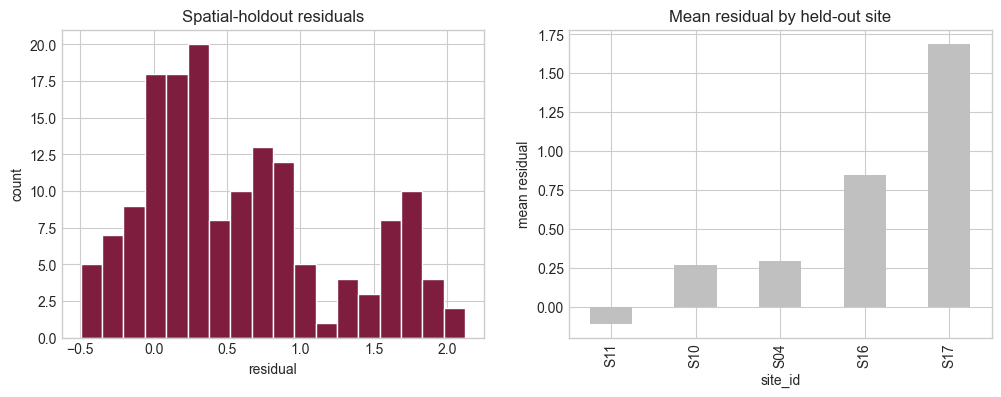

In [19]:
spatial_knn["residual"] = spatial_knn["pressure_su"] - spatial_knn["prediction"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(spatial_knn["residual"], bins=18, color="#7f1d3f", edgecolor="white")
axes[0].set(title="Spatial-holdout residuals", xlabel="residual", ylabel="count")
spatial_knn.groupby("site_id")["residual"].mean().sort_values().plot.bar(ax=axes[1], color="silver")
axes[1].set(title="Mean residual by held-out site", ylabel="mean residual")
plt.show()

The spatial residuals vary by held-out site, which is expected for a boundary
holdout with uneven neighbour geometry. The result is evidence about this
partition and distance rule. It does not imply that distance is a complete
physical model or that held-out performance transfers to unseen fields.

## Change one assumption: neighbour count

We repeat only the neighbour-count choice while holding the partition, distance
metric, and weighting fixed. This sensitivity experiment identifies whether
the reported error is fragile to a small modelling choice.

In [20]:
knn_sensitivity = []
for neighbours in [3, 5, 8]:
    trial = spatial_predictions(neighbours)
    row = metric_row(
        f"distance-weighted KNN (k={neighbours})", trial, "prediction",
        "same-period spatial interpolation", "five eastern-boundary sites; all periods",
    )
    row["neighbours"] = neighbours
    knn_sensitivity.append(row)
pd.DataFrame(knn_sensitivity)

,protocol,domain,baseline,n,mae,rmse,bias,neighbours
0,same-period spatial interpolation,five eastern-boundary sites; all periods,distance-weighted KNN (k=3),157,0.666393,0.896828,0.635001,3
1,same-period spatial interpolation,five eastern-boundary sites; all periods,distance-weighted KNN (k=5),157,0.649611,0.876292,0.586843,5
2,same-period spatial interpolation,five eastern-boundary sites; all periods,distance-weighted KNN (k=8),157,0.667782,0.891687,0.576098,8


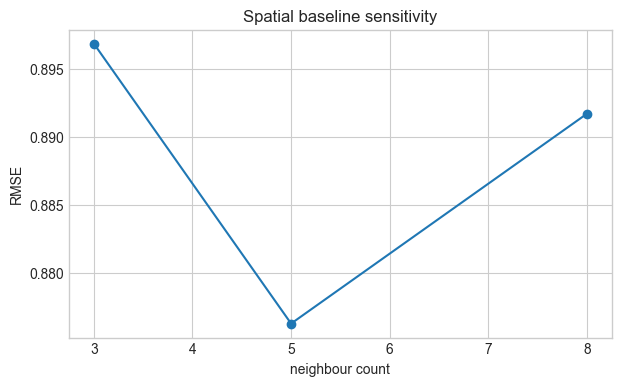

In [21]:
sensitivity_frame = pd.DataFrame(knn_sensitivity)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sensitivity_frame["neighbours"], sensitivity_frame["rmse"], marker="o")
ax.set(xlabel="neighbour count", ylabel="RMSE", title="Spatial baseline sensitivity")
plt.show()

If errors move across the tested neighbour counts, the baseline conclusion is
sensitive and should be reported with that range. If they remain close, the
evidence supports local stability only across these three choices. Neither
outcome selects a physical connectivity model.

## Empirical prediction spread, not calibrated uncertainty

For the five-neighbour baseline, we compute the standard deviation of neighbour
target values used at each prediction. This is a descriptive local spread. It
is not a confidence interval, posterior uncertainty, or coverage-calibrated
prediction interval.

In [22]:
spread_rows = []
for period, test_frame in spatial_test.groupby("period"):
    train_frame = spatial_train.query("period == @period")
    finder = NearestNeighbors(n_neighbors=5).fit(train_frame[["x_norm", "y_norm"]])
    _, indices = finder.kneighbors(test_frame[["x_norm", "y_norm"]])
    values = train_frame["pressure_su"].to_numpy()[indices]
    for row, spread in zip(test_frame.itertuples(), values.std(axis=1), strict=True):
        spread_rows.append({"site_id": row.site_id, "period": row.period, "empirical_spread": spread})
spread = pd.DataFrame(spread_rows)

In [23]:
spatial_with_spread = spatial_knn.merge(spread, on=["site_id", "period"], validate="one_to_one")
spatial_with_spread["absolute_error"] = spatial_with_spread["residual"].abs()
spatial_with_spread[["empirical_spread", "absolute_error"]].describe()

,empirical_spread,absolute_error
count,157.000000,157.000000
mean,0.506949,0.649611
std,0.090717,0.590008
min,0.233036,0.002792
25%,0.431177,0.193452
50%,0.526447,0.442042
75%,0.570920,0.908916
max,0.709810,2.121128


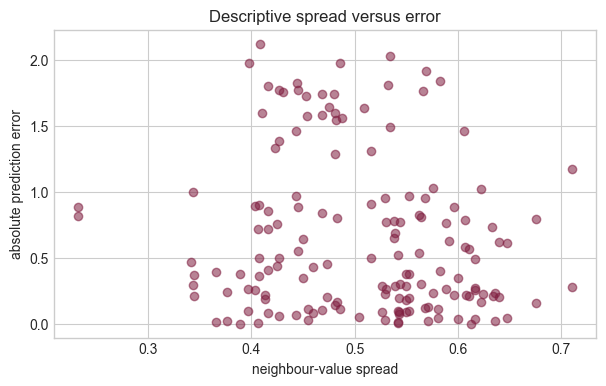

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(spatial_with_spread["empirical_spread"], spatial_with_spread["absolute_error"], alpha=0.55, color="#7f1d3f")
ax.set(xlabel="neighbour-value spread", ylabel="absolute prediction error", title="Descriptive spread versus error")
plt.show()

In [25]:
inside_one_spread = spatial_with_spread["absolute_error"] <= spatial_with_spread["empirical_spread"]
pd.Series({
    "fraction inside prediction ± spread": inside_one_spread.mean(),
    "error-spread correlation": spatial_with_spread[["absolute_error", "empirical_spread"]].corr().iloc[0, 1],
})

fraction inside prediction ± spread    0.541401
error-spread correlation              -0.154245
dtype: float64

The descriptive coverage and correlation are empirical diagnostics. They do
not establish statistical calibration because the interval was neither derived
from a probability model nor calibrated on an independent set. This distinction
prevents ordinary neighbour variability from being overstated as uncertainty
quantification.

## Reproducibility and consolidated evidence

We repeat the deterministic KNN calculation and compare arrays directly. The
final table keeps chronological and spatial questions labelled separately so a
reader does not mistake their errors for interchangeable evidence.

In [26]:
repeat_knn = spatial_predictions(5)
np.testing.assert_allclose(spatial_knn["prediction"], repeat_knn["prediction"])
"deterministic predictions confirmed"

'deterministic predictions confirmed'

In [27]:
all_metrics = pd.concat([
    chronological_metrics,
    pd.DataFrame([spatial_metrics]),
], ignore_index=True)
scorecard_columns = ["protocol", "domain", "baseline", "n", "mae", "rmse", "bias"]
all_metrics = all_metrics[scorecard_columns]
all_metrics

,protocol,domain,baseline,n,mae,rmse,bias
0,chronological prediction,periods 28–35; observed test rows,per-site linear trend,178,0.225458,0.269812,-0.065418
1,chronological prediction,periods 28–35; observed test rows,per-site persistence,178,0.320228,0.395955,-0.261640
2,chronological prediction,periods 28–35; observed test rows,global mean,178,0.602560,0.802759,0.402273
3,same-period spatial interpolation,five eastern-boundary sites; all periods,distance-weighted KNN (k=5),157,0.649611,0.876292,0.586843


In [28]:
output_dir = Path("data/generated")
all_metrics.to_csv(output_dir / "baseline_metrics.csv", index=False, float_format="%.8f")
sensitivity_frame.to_csv(output_dir / "knn_sensitivity.csv", index=False, float_format="%.8f")

## Conclusion and limitations

The evidence supports using transparent baselines as diagnostic references.
The chronological baselines reveal temporal assumption failures; the spatial
KNN baseline reveals boundary and neighbour sensitivity; residual plots expose
patterns hidden by aggregate metrics. Empirical neighbour spread remains
descriptive and is not statistically calibrated uncertainty.

The hypotheses are therefore only partly supported: simple structure is
predictable in this synthetic experiment, but no baseline resolves every
spatial-temporal pattern. These results do not validate a private model,
operational field behavior, causal mechanisms, or deployment performance. A
future R1 could compare a small graph-temporal research model only after its
contract, leakage controls, and public provenance are separately approved.